In [80]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import statsmodels.graphics.tsaplots as tsp
import statsmodels.stats.api as sms
import statsmodels.tsa.arima.model as sma
from pmdarima import auto_arima

plt.rcParams["figure.figsize"] = (11, 3)

In [81]:
def acf_pacf(y):
    plt.clf()
    _, axes = plt.subplots(1, 2)
    tsp.plot_acf(y, zero=False, ax=axes[0], bartlett_confint=False)
    tsp.plot_pacf(y, zero=False, ax=axes[1], method="ywm")
    plt.show()

In [82]:
eps = np.random.normal(size=500)

In [83]:
y = np.zeros(2 + 500)
e = np.append([0, 0], eps)

for t in range(2, 502):
    y[t] = 1 + 1.2 * y[t - 1] - 0.35 * y[t - 2] + e[t] + 0.5 * e[t - 1]

y = y[102:]

<Figure size 1100x300 with 0 Axes>

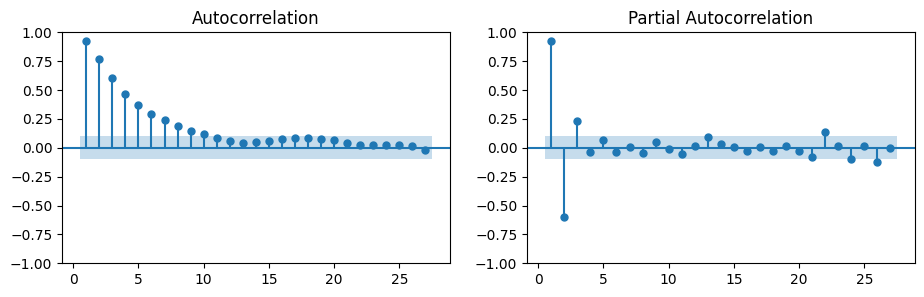

In [84]:
acf_pacf(y)

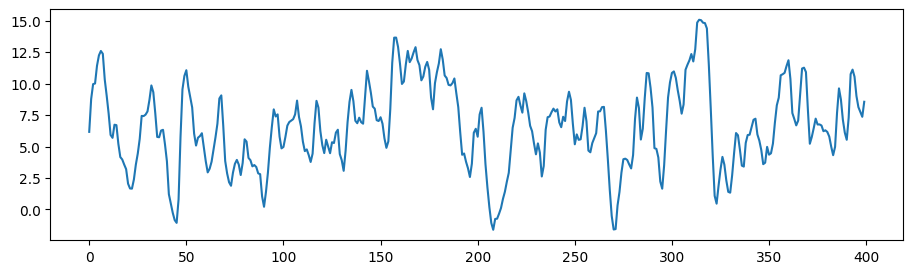

In [85]:
plt.plot(y)

Оцениванием AR при помощи МНК

In [86]:
model = smf.ols(
    "y ~ y.shift(1) + y.shift(2) +  y.shift(3) +  y.shift(4)",
    data=pd.DataFrame({"y": y}),
).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     1080.
Date:                Thu, 02 Apr 2026   Prob (F-statistic):          9.26e-210
Time:                        16:02:06   Log-Likelihood:                -544.51
No. Observations:                 396   AIC:                             1099.
Df Residuals:                     391   BIC:                             1119.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.6097      0.119      5.131      0.0

In [87]:
model = smf.ols(
    "y ~ y.shift(1) + y.shift(2) +  y.shift(3)",
    data=pd.DataFrame({"y": y}),
).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.917
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     1446.
Date:                Thu, 02 Apr 2026   Prob (F-statistic):          7.37e-212
Time:                        16:05:21   Log-Likelihood:                -546.05
No. Observations:                 397   AIC:                             1100.
Df Residuals:                     393   BIC:                             1116.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.5767      0.115      5.011      0.0

Оцениваем модели при помощи ММП

In [88]:
model = sma.ARIMA(y, order=(4, 0, 0)).fit()
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  400
Model:                 ARIMA(4, 0, 0)   Log Likelihood                -551.715
Date:                Thu, 02 Apr 2026   AIC                           1115.430
Time:                        16:15:49   BIC                           1139.379
Sample:                             0   HQIC                          1124.914
                                - 400                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.5891      0.524     12.577      0.000       5.562       7.616
ar.L1          1.6632      0.050     33.446      0.000       1.566       1.761
ar.L2         -1.0521      0.094    -11.212      0.0

In [89]:
model = sma.ARIMA(y, order=(3, 0, 0)).fit()
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  400
Model:                 ARIMA(3, 0, 0)   Log Likelihood                -552.371
Date:                Thu, 02 Apr 2026   AIC                           1114.741
Time:                        16:22:42   BIC                           1134.698
Sample:                             0   HQIC                          1122.644
                                - 400                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.5984      0.553     11.925      0.000       5.514       7.683
ar.L1          1.6484      0.048     34.565      0.000       1.555       1.742
ar.L2         -0.9949      0.080    -12.420      0.0

In [90]:
model = sma.ARIMA(y, order=(2, 0, 0)).fit()
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  400
Model:                 ARIMA(2, 0, 0)   Log Likelihood                -565.940
Date:                Thu, 02 Apr 2026   AIC                           1139.881
Time:                        16:23:54   BIC                           1155.847
Sample:                             0   HQIC                          1146.204
                                - 400                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.5784      0.426     15.431      0.000       5.743       7.414
ar.L1          1.4910      0.039     37.840      0.000       1.414       1.568
ar.L2         -0.6106      0.038    -16.130      0.0

In [91]:
model = sma.ARIMA(y, order=(2, 0, 1)).fit()
print(model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                  400
Model:                 ARIMA(2, 0, 1)   Log Likelihood                -550.928
Date:                Thu, 02 Apr 2026   AIC                           1111.855
Time:                        16:24:51   BIC                           1131.812
Sample:                             0   HQIC                          1119.758
                                - 400                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.5926      0.506     13.016      0.000       5.600       7.585
ar.L1          1.2392      0.068     18.339      0.000       1.107       1.372
ar.L2         -0.3778      0.065     -5.800      0.0

Читерство: авто-АРИМА

In [92]:
model_auto = auto_arima(y)

In [94]:
model_auto.order

(2, 0, 1)

Характеристические корни

In [95]:
1 / model.arroots

array([0.69795505, 0.54127645])

In [96]:
1 / model.maroots

array([-0.43323343])

In [97]:
model_auto.arroots(), model_auto.maroots()

(array([1.43263226, 1.84773268]), array([-2.30813991]))

Тест Харке-Бера

In [98]:
sms.jarque_bera(model.resid)

(np.float64(2.792246271506921),
 np.float64(0.24755484247719178),
 np.float64(0.16042976244520185),
 np.float64(2.7458662919297803))

Тест Колмогорова-Смирнова (Лильефорса)

In [99]:
sms.lilliefors(model.resid)

(np.float64(0.038092168114642055), np.float64(0.18810541259914457))

Тест Льюнг-Бокса

In [100]:
sms.acorr_ljungbox(model.resid, boxpierce=True)

,lb_stat,lb_pvalue,bp_stat,bp_pvalue
1,0.009726,0.921439,0.009654,0.921732
2,0.071597,0.964835,0.070909,0.965167
3,0.084915,0.993584,0.084062,0.993679
4,1.229463,0.873224,1.211526,0.876197
5,1.310733,0.933823,1.291381,0.935816
6,1.353546,0.968623,1.333342,0.969787
7,2.865477,0.897161,2.811424,0.901882
8,3.519434,0.897676,3.449114,0.903103
9,3.956463,0.914255,3.874184,0.919496
10,4.073866,0.943953,3.988082,0.947883


Тест Бройша-Годфри

In [101]:
sms.acorr_breusch_godfrey(model)

(np.float64(3.9261704151294374),
 np.float64(0.9506160983731327),
 0.3856049497352869,
 0.9527511633212878)

ARCH-LM тест

In [102]:
sms.het_arch(model.resid, ddof=3)

(np.float64(12.014914982279016),
 np.float64(0.2840595362892085),
 1.2143557064592458,
 0.27983305601008623)

Сгенерируем процесс с сезонной автокорреляцией
$$(1-0.5L^4)(1-0.7L)(1-0.5L)y_t = \mu + (1+0.5L)\varepsilon_t$$

In [106]:
s = np.zeros(6 + 5000)
u = np.append([0] * 6, np.random.normal(size=5000))

for t in range(5, 5005):
    s[t] = (
        1
        + 1.2 * s[t - 1]
        - 0.35 * s[t - 2]
        + 0.5 * s[t - 4]
        - 0.6 * s[t - 5]
        + 0.175 * s[t - 6]
        + u[t]
        + 0.5 * u[t - 1]
    )

s = s[4005:]

In [107]:
model = auto_arima(s, m=4)

In [108]:
model.order, model.seasonal_order

((2, 0, 1), (1, 0, 0, 4))